# 03 — Expansion signals: which Basic accounts look like upgraders

**Revenue Analytics · data as of 30 Sep 2026 · synthetic data** (see `docs/data_model.md`)
Request: *"Which accounts should the CS team prioritize?"* — the expansion side (`docs/01_request_and_scope.md`, question Q5; rules in `docs/02_metric_definitions.md §13`)

In [1]:
import numpy as np
import pandas as pd
from saas_rev import marts, theme
from saas_rev.nbutil import md, setup, show
from saas_rev.analysis import expansion as E
from saas_rev.theme import money, pct, pts
setup()
k = E.key_numbers()
sig = marts.load('expansion__signal_table')
s = sig.set_index('signal')
mm = marts.load('expansion__model_metrics').set_index('period')
cal = marts.load('expansion__calibration')
opp = marts.load('expansion__opportunities')

## TL;DR

In [2]:
top_dec = cal[cal['period'] == 'all'].iloc[-1]
auc_overlap = k['auc_test_post_lo'] <= k['auc_test_pre_hi'] and k['auc_test_pre_lo'] <= k['auc_test_post_hi']
md(f"""
- **Upgraders look different in the 13 weeks before they upgrade, mostly in how hard they push against the Premium paywall.**
  Comparing {k['n_upgraders']} upgraders with {k['n_stayers']} stayers matched on calendar month and tenure band, the share of active users
  who hit the paywall has a standardized mean difference of {s.loc['gate_user_share','smd']:.2f} (95% interval {s.loc['gate_user_share','smd_lo']:.2f}–{s.loc['gate_user_share','smd_hi']:.2f};
  median {pct(s.loc['gate_user_share','median_upgraders'], 0)} of active users vs {pct(s.loc['gate_user_share','median_stayers'], 0)}), paywall hits per active user {s.loc['gate_hits_per_wau','smd']:.2f}
  and automation runs per active user {s.loc['automation_per_wau','smd']:.2f}. Core actions ({s.loc['core_actions_per_wau','smd']:.2f}), seats ({s.loc['seats','smd']:.2f}),
  seat growth ({s.loc['seat_growth_3m','smd']:.2f}) and utilization ({s.loc['utilization_13w','smd']:.2f}) are small; invitations, integrations, report views and the WAU trend do not separate the groups.
- **On the full population, the top quintile of paywall users upgrades at {pct(s.loc['gate_user_share','top_quintile_rate'])} within 90 days, {s.loc['gate_user_share','top_quintile_lift']:.1f}× the {pct(k['base_rate_all'])} base rate (account-level bootstrap interval {s.loc['gate_user_share','top_quintile_lift_lo']:.1f}–{s.loc['gate_user_share','top_quintile_lift_hi']:.1f}×).**
  Accounts that added seats in the last three months upgrade at {s.loc['seat_growth_3m','top_quintile_lift']:.1f}× ({pct(s.loc['seat_growth_3m','top_quintile_rate'])}).
- **The April 2026 packaging change moved the paywall.** Paywall hits per active user fell {pct(-k['gate_hits_drift'], 0)} ({k['gate_hits_mean_pre']:.2f} → {k['gate_hits_mean_post']:.2f} per week)
  and automation runs per active user rose {pct(k['automation_drift'], 0)}. Measured *within* each period the lift of the paywall, automation and core-action signals holds
  ({len(k['signals_lift_holds_post'])} of 12 signals keep an interval above 1×); absolute thresholds do not. CS rules must be relative: "top decile this month".
- **A plain logistic regression ranks accounts usefully but is not a forecast.** Test AUC {k['auc_test']:.2f} (95% {k['auc_test_lo']:.2f}–{k['auc_test_hi']:.2f}), {k['auc_test_pre']:.2f} before April and {k['auc_test_post']:.2f} after, with {'overlapping' if auc_overlap else 'non-overlapping'} account-level intervals.
  Working the 100 highest-scored Basic accounts a month finds {pct(k['precision_at_100_all'])} upgraders ({k['lift_at_100_all']:.1f}× the base rate) and {pct(k['recall_at_100_all'], 0)} of all upgrades;
  the top score decile is over-confident (predicted {pct(top_dec['predicted'])}, observed {pct(top_dec['observed'])}).
- **Opportunity list at 30 Sep 2026:** {k['n_opportunities']:,} Basic accounts scored, {k['opportunities_expected_upgrades']:.0f} expected upgrades worth {money(k['opportunities_expected_mrr'])} MRR
  over 90 days. The top 100 by expected MRR hold {k['capacity_expected_upgrades']:.1f} expected upgrades ({money(k['capacity_expected_mrr'])} MRR, {pct(k['capacity_share_of_expected_mrr'], 0)} of the list's value);
  if all 100 upgraded the ceiling is {money(k['capacity_incremental_mrr_if_all'])} MRR.
""")


- **Upgraders look different in the 13 weeks before they upgrade, mostly in how hard they push against the Premium paywall.**
  Comparing 347 upgraders with 347 stayers matched on calendar month and tenure band, the share of active users
  who hit the paywall has a standardized mean difference of 0.86 (95% interval 0.72–1.02;
  median 17% of active users vs 6%), paywall hits per active user 0.82
  and automation runs per active user 0.64. Core actions (0.16), seats (0.21),
  seat growth (0.12) and utilization (0.20) are small; invitations, integrations, report views and the WAU trend do not separate the groups.
- **On the full population, the top quintile of paywall users upgrades at 9.5% within 90 days, 2.4× the 4.0% base rate (account-level bootstrap interval 2.1–2.7×).**
  Accounts that added seats in the last three months upgrade at 1.4× (5.6%).
- **The April 2026 packaging change moved the paywall.** Paywall hits per active user fell 61% (0.21 → 0.08 per week)
  and automation runs per active user rose 188%. Measured *within* each period the lift of the paywall, automation and core-action signals holds
  (4 of 12 signals keep an interval above 1×); absolute thresholds do not. CS rules must be relative: "top decile this month".
- **A plain logistic regression ranks accounts usefully but is not a forecast.** Test AUC 0.68 (95% 0.62–0.72), 0.66 before April and 0.69 after, with overlapping account-level intervals.
  Working the 100 highest-scored Basic accounts a month finds 6.3% upgraders (2.5× the base rate) and 16% of all upgrades;
  the top score decile is over-confident (predicted 14.4%, observed 5.5%).
- **Opportunity list at 30 Sep 2026:** 1,997 Basic accounts scored, 41 expected upgrades worth $8.0K MRR
  over 90 days. The top 100 by expected MRR hold 6.1 expected upgrades ($2.5K MRR, 31% of the list's value);
  if all 100 upgraded the ceiling is $46.0K MRR.


## Question
Which Basic accounts show pre-upgrade behaviour, and what are those signals? Two decisions depend on the answer:
1. **Head of Customer Success — Q1 2027 coverage plan** (capacity ≈ 120 proactive reviews a quarter): which Basic accounts go on the
   *expansion* side of the account health list, ranked, with reason codes a CSM can say to the customer.
2. **Head of Product / Pricing — pricing council, Dec 2026:** the April 2026 packaging change moved advanced automations into Basic. Do the
   upgrade signals still work, and what is the upgrade trigger now?

Every input is observable at the index month-end; nothing after it is used (`02_metric_definitions.md §13`).

## Data
| Table (SQL file) | Grain | Used for |
|---|---|---|
| `fct_account_month_features` (`sql/41`) | paying account × month-end *t* | behaviour in the 13 complete weeks ending at *t*, seats and terms at *t* and *t − 3*, static attributes; `label_*` outcomes |
| `fct_change_components` (`sql/22`) | plan change | the Basic → Premium upgrade events and whether they were voluntary (`change_source ≠ 'system'`) |
| `fct_account_usage_weekly` (`sql/40`) | account × week | weekly paywall hits per active user for the drift chart |
| `stg_customers`, `int_next_renewal` (`sql/01`, `sql/11`) | account | company name, CSM owner, next renewal date on the opportunity list |
| `expansion__*` (`src/saas_rev/analysis/expansion.py`) | derived | population, matched comparison, signal table, quintiles, drift, model outputs, opportunity list |

Internal / test accounts are excluded upstream. Usage windows use complete weeks only; the partial week of 28–30 Sep 2026 is out.

## Method
- **Population** (§13): month-ends at which the account pays for Basic with ≥ 3 months since its first paid month-end and a fully observed
  90-day window (Jan 2024 – Jun 2026). **Label** = a voluntary Basic → Premium upgrade effective in (*t*, *t* + 90 days]. Rows whose window holds a
  forced seat-cap upgrade are reported separately and left out. Churn inside the window stays in the ranking population as a non-upgrade
  (it is not known at *t*), but never serves as a matched control.
- **Upgraders vs stayers.** Upgraders = the last month-end before each eligible upgrade (one row per upgrade). Stayers = one eligible month-end
  per account that neither upgraded nor churned in its window, drawn 1:1 from the same calendar-month × tenure-band stratum (bands 3–6, 7–12,
  13–24, 25+ months) with a fixed seed; stayer accounts never appear among the upgraders. Matching on calendar month removes the April change
  and the base-rate trend from the comparison; matching on tenure removes account age.
- **Per signal:** medians of both groups, the standardized mean difference (difference in means ÷ pooled SD) with a 1,000-draw bootstrap 95%
  interval, and the 90-day upgrade rate by quintile on the full population with lift = bin rate ÷ base rate. A value that holds 20% or
  more of the rows (zero seat growth, 100% peak utilization) gets its own bin so the bins above it keep their meaning, and a bin thinner than
  5% of rows (the sliver above 100% peak utilization) is merged into the bin below it, so the top bin is a rule CS could state ("at least one
  full-seat week"). Bin rates and lifts carry an **account-level bootstrap** 95% interval (1,000 draws: accounts resampled with replacement,
  their rows kept together, bin edges fixed), because an account contributes about ten month-end rows that are not independent evidence —
  a Wilson interval on rows would read tighter than the data support.
- **Drift check:** weekly paywall hits per active user across Basic accounts around 15 Apr 2026; the before / after distribution of the three
  packaging-sensitive signals; and each signal's top-bin lift recomputed within the pre and post periods (post = month-ends Apr – Jun 2026,
  whose 13-week windows contain post-change weeks).
- **Propensity model:** logistic regression (scikit-learn, L2 with the default C = 1, no tuning, `class_weight=None`), standardized features,
  rows weighted 1 ÷ rows per account so every account has one vote. Features: the twelve signals (the three paywall / automation signals as
  within-month percentile ranks, because their levels moved with the packaging change; right-skewed rates as log(1 + x)), log tenure, prior
  Premium / Enterprise tier, annual billing, segment and Paid Social channel. The per-account weights centre the intercept on the per-account
  prevalence, so it is re-centred once on the row-level base rate of the training months (one parameter; CS lists are drawn per month).
  **Purged time split:** train on month-ends ≤ 30 Sep 2025, hold out Oct – Dec 2025, test on 31 Jan – 30 Jun 2026, metrics reported before and
  after 15 Apr 2026 by index month-end: 'before' = month-ends through 31 Mar (90-day labels run to 29 Jun, so 43 of 124 upgrades post-date
  the change); 'after' = Apr – Jun, whose feature windows contain post-change weeks. The three held-out month-ends equal the 90-day label horizon: without them an upgrade in Jan – Mar 2026 would be a
  training label (through the Oct – Dec rows of the same account) and a test label at once, and the back-test would flatter the model. Odds
  ratios per 1 SD and the test AUC carry an account-level bootstrap interval (300 draws).
- **Opportunity list:** every Basic account paying at 30 Sep 2026 with ≥ 3 months tenure, scored by the same model refit on all labelled rows (held-out
  months included — the embargo protects the back-test, not the scorer) and re-centred on the observed post-change base rate (Apr – Jun 2026 month-ends). Expected MRR = propensity × seats × (Premium − Basic list price
  per seat-month on the account's billing period: $20 monthly, $16 annual). Reason codes = the two or three behavioural signals that add most
  to the score relative to the average account, each stated at the strongest threshold the account meets.

## Results
### 1. Upgraders vs matched stayers

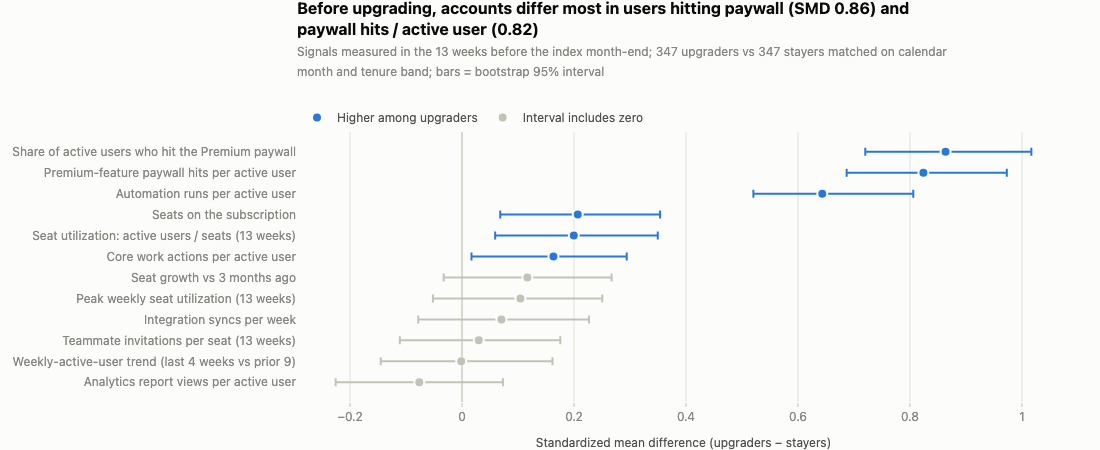

In [3]:
show(E.fig_smd_dotplot(sig))

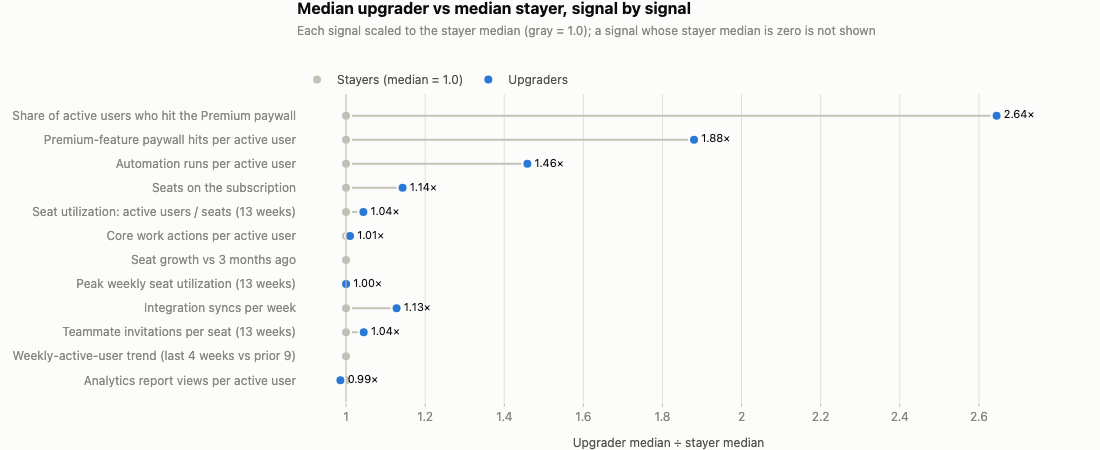

In [4]:
show(E.fig_group_medians(sig))

In [5]:
sig[['name', 'n_upgraders', 'n_stayers', 'median_upgraders', 'median_stayers', 'smd', 'smd_lo', 'smd_hi']]

,name,n_upgraders,n_stayers,median_upgraders,median_stayers,smd,smd_lo,smd_hi
0,Share of active users who hit the Premium paywall,346,347,0.1653,0.0625,0.8636,0.7202,1.0168
1,Premium-feature paywall hits per active user,346,347,0.2960,0.1575,0.8240,0.6869,0.9730
2,Automation runs per active user,346,347,0.8220,0.5636,0.6434,0.5203,0.8059
3,Seats on the subscription,347,347,8.0000,7.0000,0.2066,0.0682,0.3537
4,Seat utilization: active users / seats (13 weeks),347,347,0.6985,0.6692,0.1996,0.0591,0.3496
5,Core work actions per active user,346,347,15.3865,15.2340,0.1632,0.0169,0.2942
6,Seat growth vs 3 months ago,346,345,0.0000,0.0000,0.1167,-0.0328,0.2671
7,Peak weekly seat utilization (13 weeks),347,347,0.9286,0.9286,0.1043,-0.0520,0.2505
8,Integration syncs per week,347,347,47.5385,42.1538,0.0702,-0.0782,0.2267
9,Teammate invitations per seat (13 weeks),347,347,0.2321,0.2222,0.0298,-0.1111,0.1755


In [6]:
ex = k['upgrade_events_excluded']
md(f"""**Reading.** Of {k['voluntary_upgrade_events']} voluntary Basic → Premium upgrades, {k['upgrade_events_in_comparison']} have an eligible
month-end before them; the rest are excluded by the rules in §13 — {ex['tenure under 3 months']} upgraded within three months of first payment,
{ex['no paid month-end before the upgrade']} in their first paid month, {ex['90-day window not complete']} after June 2026, {ex['not on Basic at the prior month-end']} were not
on Basic at the prior month-end. {k['forced_upgrade_events']} forced seat-cap upgrades are reported separately. The {k['n_upgraders']} upgraders and
{k['n_stayers']} stayers are matched in {k['n_strata']} calendar-month × tenure-band strata, so neither the April change nor account age drives the gaps.

The three usage signals of *demand for Premium features* dominate: a typical upgrader has {pct(s.loc['gate_user_share','median_upgraders'], 0)} of its active users
hitting the paywall vs {pct(s.loc['gate_user_share','median_stayers'], 0)} for a stayer, {s.loc['gate_hits_per_wau','median_upgraders']:.2f} vs {s.loc['gate_hits_per_wau','median_stayers']:.2f} hits
per active user, and {s.loc['automation_per_wau','median_upgraders']:.2f} vs {s.loc['automation_per_wau','median_stayers']:.2f} automation runs per active user. The *team-growth*
signals are present but small: seats {s.loc['seats','median_upgraders']:.0f} vs {s.loc['seats','median_stayers']:.0f} (SMD {s.loc['seats','smd']:.2f}), seat growth SMD {s.loc['seat_growth_3m','smd']:.2f}
(both medians are zero: most accounts do not change seats in any given quarter), utilization {pct(s.loc['utilization_13w','median_upgraders'], 0)} vs
{pct(s.loc['utilization_13w','median_stayers'], 0)}. Invitations per seat, integration syncs, report views and the WAU trend have intervals that include zero.
These are differences in behaviour before an upgrade, not causes of it.""")

**Reading.** Of 532 voluntary Basic → Premium upgrades, 347 have an eligible
month-end before them; the rest are excluded by the rules in §13 — 131 upgraded within three months of first payment,
30 in their first paid month, 22 after June 2026, 2 were not
on Basic at the prior month-end. 10 forced seat-cap upgrades are reported separately. The 347 upgraders and
347 stayers are matched in 81 calendar-month × tenure-band strata, so neither the April change nor account age drives the gaps.

The three usage signals of *demand for Premium features* dominate: a typical upgrader has 17% of its active users
hitting the paywall vs 6% for a stayer, 0.30 vs 0.16 hits
per active user, and 0.82 vs 0.56 automation runs per active user. The *team-growth*
signals are present but small: seats 8 vs 7 (SMD 0.21), seat growth SMD 0.12
(both medians are zero: most accounts do not change seats in any given quarter), utilization 70% vs
67%. Invitations per seat, integration syncs, report views and the WAU trend have intervals that include zero.
These are differences in behaviour before an upgrade, not causes of it.

### 2. Upgrade rate by signal quintile, full population

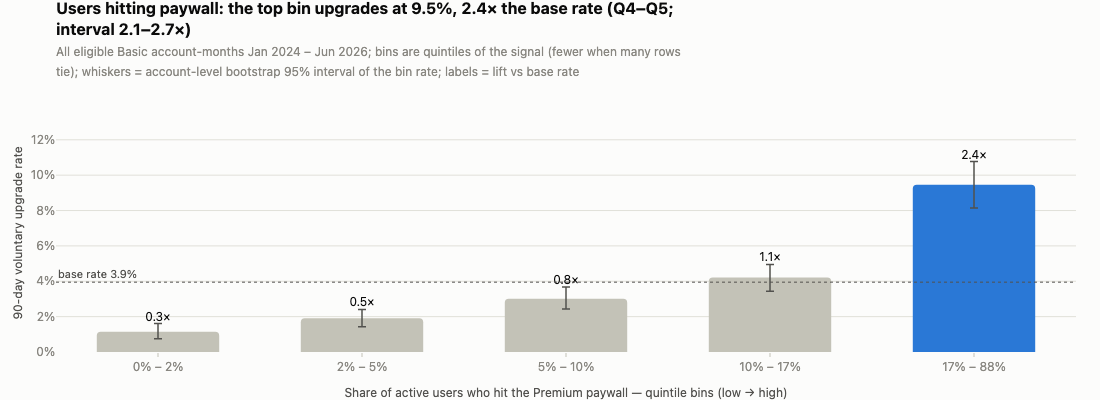

In [7]:
show(E.fig_quintile_lift('gate_user_share', 'all'))

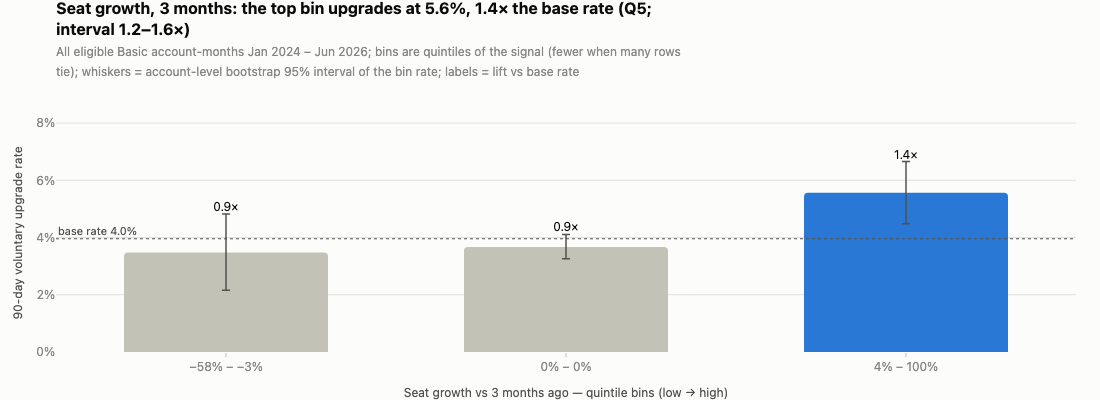

In [8]:
show(E.fig_quintile_lift('seat_growth_3m', 'all'))

In [9]:
sig[['name', 'top_quintile_rate', 'top_quintile_lift', 'top_quintile_lift_lo', 'top_quintile_lift_hi']].sort_values('top_quintile_lift', ascending=False)

,name,top_quintile_rate,top_quintile_lift,top_quintile_lift_lo,top_quintile_lift_hi
0,Share of active users who hit the Premium paywall,0.0946,2.3940,2.1404,2.6594
1,Premium-feature paywall hits per active user,0.0925,2.3424,2.0768,2.6027
2,Automation runs per active user,0.0658,1.6659,1.4424,1.8957
6,Seat growth vs 3 months ago,0.0557,1.4068,1.1810,1.6440
4,Seat utilization: active users / seats (13 weeks),0.0546,1.3813,1.1759,1.5902
5,Core work actions per active user,0.0538,1.3621,1.1446,1.5738
3,Seats on the subscription,0.0465,1.1754,0.9930,1.3705
8,Integration syncs per week,0.0434,1.0972,0.8969,1.3100
9,Teammate invitations per seat (13 weeks),0.0431,1.0903,0.9170,1.2725
7,Peak weekly seat utilization (13 weeks),0.0408,1.0321,0.9174,1.1376


In [10]:
quint = marts.load('expansion__quintiles')
peak_top = quint[(quint['signal'] == 'max_weekly_utilization_13w') & (quint['period'] == 'all')].iloc[-1]
noise = [E.SIGNALS[x]['short'].lower().replace('wau', 'WAU') for x in sig.loc[(sig['top_quintile_lift_lo'] <= 1) & (sig['top_quintile_lift_hi'] >= 1), 'signal']]
md(f"""**Reading.** The lift table is the matched comparison re-expressed as a CS rule on all {k['population_rows']:,} eligible account-months
({k['population_accounts']:,} accounts, base rate {pct(k['base_rate_all'])}): the top quintile of paywall users upgrades at {pct(s.loc['gate_user_share','top_quintile_rate'])}
({s.loc['gate_user_share','top_quintile_lift']:.1f}×, account-level bootstrap interval {s.loc['gate_user_share','top_quintile_lift_lo']:.1f}–{s.loc['gate_user_share','top_quintile_lift_hi']:.1f}×), paywall hits per
active user {s.loc['gate_hits_per_wau','top_quintile_lift']:.1f}×, automation runs {s.loc['automation_per_wau','top_quintile_lift']:.1f}×. Seat growth is a rarer but real signal: only
the accounts that added seats (the top bin, about one row in six) stand out, at {s.loc['seat_growth_3m','top_quintile_lift']:.1f}× — the flat majority sits at the base rate.
Seat utilization's top quintile is at {s.loc['utilization_13w','top_quintile_lift']:.1f}×. Peak weekly utilization's top bin is "at least one full-seat week"
({pct(peak_top['share_of_rows'], 0)} of rows, {peak_top['lift']:.2f}×, {peak_top['lift_lo']:.2f}–{peak_top['lift_hi']:.2f}×): the 1% of rows above 100% are merged into it, so the
signal is not judged on a sliver. Signals whose top-bin interval includes 1× — {', '.join(noise)} — are not worth a CS rule on their own.""")

**Reading.** The lift table is the matched comparison re-expressed as a CS rule on all 24,541 eligible account-months
(2,471 accounts, base rate 4.0%): the top quintile of paywall users upgrades at 9.5%
(2.4×, account-level bootstrap interval 2.1–2.7×), paywall hits per
active user 2.3×, automation runs 1.7×. Seat growth is a rarer but real signal: only
the accounts that added seats (the top bin, about one row in six) stand out, at 1.4× — the flat majority sits at the base rate.
Seat utilization's top quintile is at 1.4×. Peak weekly utilization's top bin is "at least one full-seat week"
(43% of rows, 1.03×, 0.92–1.14×): the 1% of rows above 100% are merged into it, so the
signal is not judged on a sliver. Signals whose top-bin interval includes 1× — seats, peak weekly utilization, integration syncs / week, invites / seat, WAU trend, report views / active user — are not worth a CS rule on their own.

### 3. Did the signals survive the April 2026 packaging change?

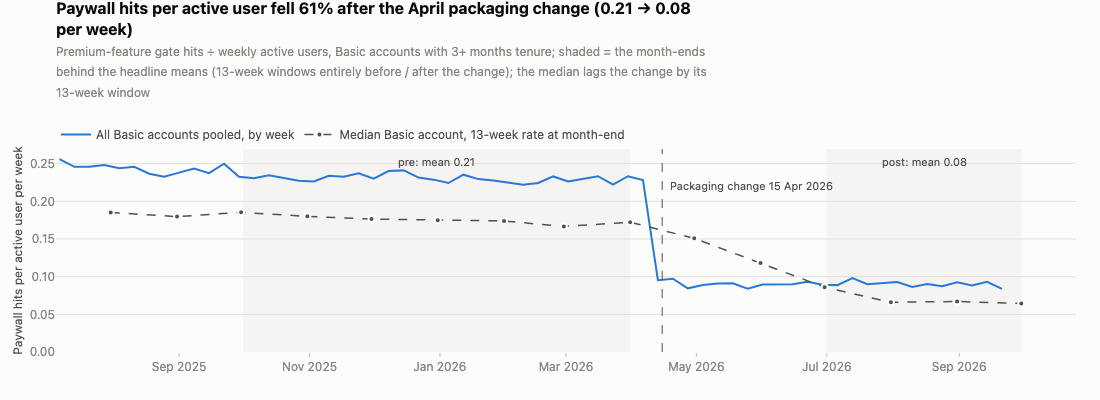

In [11]:
show(E.fig_gate_drift())

In [12]:
dd = marts.load('expansion__drift_distribution')
dd[['period', 'name', 'account_months', 'mean', 'p10', 'p50', 'p90', 'share_zero']]

,period,name,account_months,mean,p10,p50,p90,share_zero
0,pre: Oct 2025 – Mar 2026,Premium-feature paywall hits per active user,7606,0.2116,0.0588,0.1739,0.4119,0.0317
1,pre: Oct 2025 – Mar 2026,Share of active users who hit the Premium paywall,7606,0.1047,0.0000,0.0750,0.2447,0.1667
2,pre: Oct 2025 – Mar 2026,Automation runs per active user,7606,0.6198,0.3037,0.5556,1.0000,0.0013
3,post: Jul – Sep 2026,Premium-feature paywall hits per active user,5692,0.0815,0.0000,0.0662,0.1739,0.1420
4,post: Jul – Sep 2026,Share of active users who hit the Premium paywall,5692,0.0279,0.0000,0.0137,0.0784,0.4455
5,post: Jul – Sep 2026,Automation runs per active user,5692,1.7868,0.9698,1.6500,2.7851,0.0002


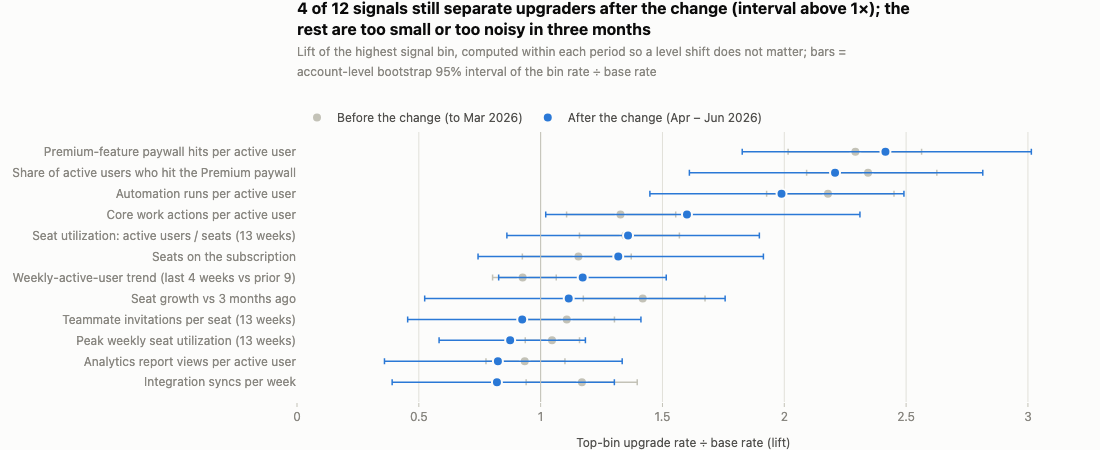

In [13]:
show(E.fig_lift_pre_post(sig))

In [14]:
holds = [E.SIGNALS[x]['short'].lower().replace('wau', 'WAU') for x in k['signals_lift_holds_post']]
pp = k['signal_lift_pre_post']
md(f"""**Reading.** Advanced automations moved into Basic on 15 Apr 2026, so the automation paywall disappeared: paywall hits per active user fell
{pct(-k['gate_hits_drift'], 0)} (mean {k['gate_hits_mean_pre']:.2f} → {k['gate_hits_mean_post']:.2f}; median {k['gate_hits_median_pre']:.2f} → {k['gate_hits_median_post']:.2f}),
the share of account-months with *no* paywall user rose from {pct(dd.iloc[1]['share_zero'], 0)} to {pct(dd.iloc[4]['share_zero'], 0)}, and automation runs per active user
rose {pct(k['automation_drift'], 0)} ({k['automation_mean_pre']:.2f} → {k['automation_mean_post']:.2f}). A rule like "more than 0.3 paywall hits per active user" that caught the top
quintile before April now catches almost nobody.

Measured within each period, the signals that still separate upgraders after the change (account-level bootstrap interval above 1×) are: {', '.join(holds)} —
paywall users {pp['gate_user_share']['pre']:.1f}× → {pp['gate_user_share']['post']:.1f}× (interval {pp['gate_user_share']['post_lo']:.1f}–{pp['gate_user_share']['post_hi']:.1f}×), paywall hits
{pp['gate_hits_per_wau']['pre']:.1f}× → {pp['gate_hits_per_wau']['post']:.1f}×, automation runs {pp['automation_per_wau']['pre']:.1f}× → {pp['automation_per_wau']['post']:.1f}×.
Seat growth ({pp['seat_growth_3m']['pre']:.1f}× → {pp['seat_growth_3m']['post']:.1f}×, interval {pp['seat_growth_3m']['post_lo']:.1f}–{pp['seat_growth_3m']['post_hi']:.1f}×) and utilization
({pp['utilization_13w']['pre']:.1f}× → {pp['utilization_13w']['post']:.1f}×) are consistent with their pre-change lift but three months with {mm.loc['post','upgrades']} upgrades
({pct(k['base_rate_test_post'])} base rate) are too few to confirm them.

**What CS should use going forward:** (1) the paywall signals and automation intensity, expressed as a percentile within the current month's
Basic population (the top decile), never as an absolute count; (2) seat additions in the last quarter as a secondary trigger; (3) nothing
from invitations, integrations, report views or the WAU trend. Thresholds should be re-based every quarter.""")

**Reading.** Advanced automations moved into Basic on 15 Apr 2026, so the automation paywall disappeared: paywall hits per active user fell
61% (mean 0.21 → 0.08; median 0.17 → 0.07),
the share of account-months with *no* paywall user rose from 17% to 45%, and automation runs per active user
rose 188% (0.62 → 1.79). A rule like "more than 0.3 paywall hits per active user" that caught the top
quintile before April now catches almost nobody.

Measured within each period, the signals that still separate upgraders after the change (account-level bootstrap interval above 1×) are: users hitting paywall, paywall hits / active user, automations / active user, core actions / active user —
paywall users 2.3× → 2.2× (interval 1.6–2.8×), paywall hits
2.3× → 2.4×, automation runs 2.2× → 2.0×.
Seat growth (1.4× → 1.1×, interval 0.5–1.8×) and utilization
(1.3× → 1.4×) are consistent with their pre-change lift but three months with 103 upgrades
(2.1% base rate) are too few to confirm them.

**What CS should use going forward:** (1) the paywall signals and automation intensity, expressed as a percentile within the current month's
Basic population (the top decile), never as an absolute count; (2) seat additions in the last quarter as a secondary trigger; (3) nothing
from invitations, integrations, report views or the WAU trend. Thresholds should be re-based every quarter.

### 4. Propensity model: ranking, capacity trade-off, calibration

In [15]:
mm[['rows', 'upgrades', 'base_rate', 'auc', 'precision_at_100', 'recall_at_100', 'lift_at_100', 'precision_at_200', 'recall_at_200', 'lift_at_200',
    'upgrades_per_month_at_100', 'mrr_covered_per_month_at_100']].T

period,all,pre,post
rows,"8,961.0000","4,128.0000","4,833.0000"
upgrades,227.0000,124.0000,103.0000
base_rate,0.0253,0.0300,0.0213
auc,0.6765,0.6629,0.6903
precision_at_100,0.0633,0.0700,0.0567
recall_at_100,0.1632,0.1640,0.1624
lift_at_100,2.5001,2.3303,2.6589
precision_at_200,0.0525,0.0567,0.0483
recall_at_200,0.2728,0.2673,0.2783
lift_at_200,2.0725,1.8865,2.2679


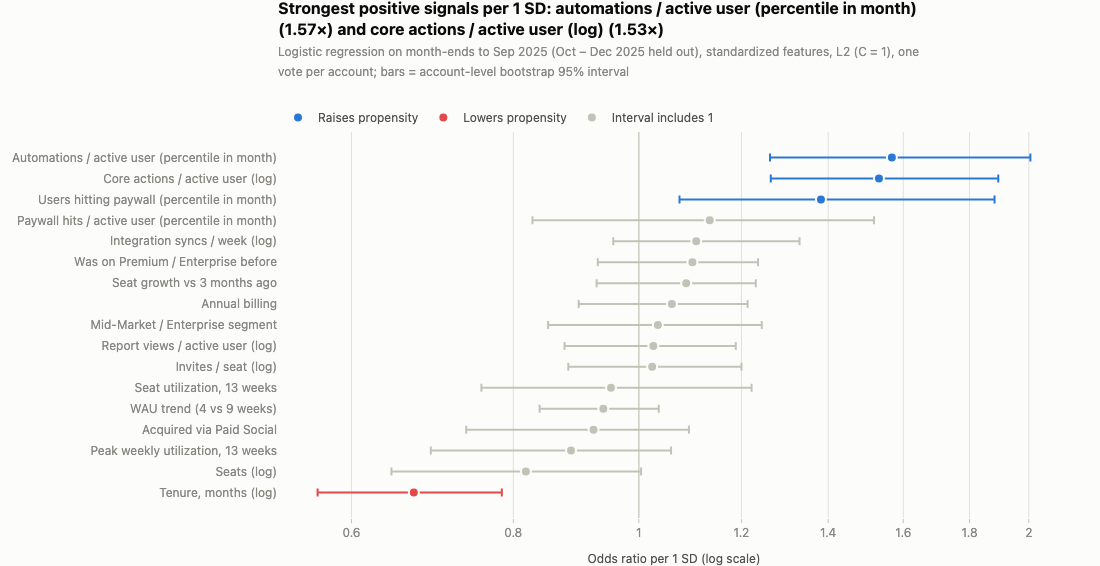

In [16]:
show(E.fig_odds_ratios())

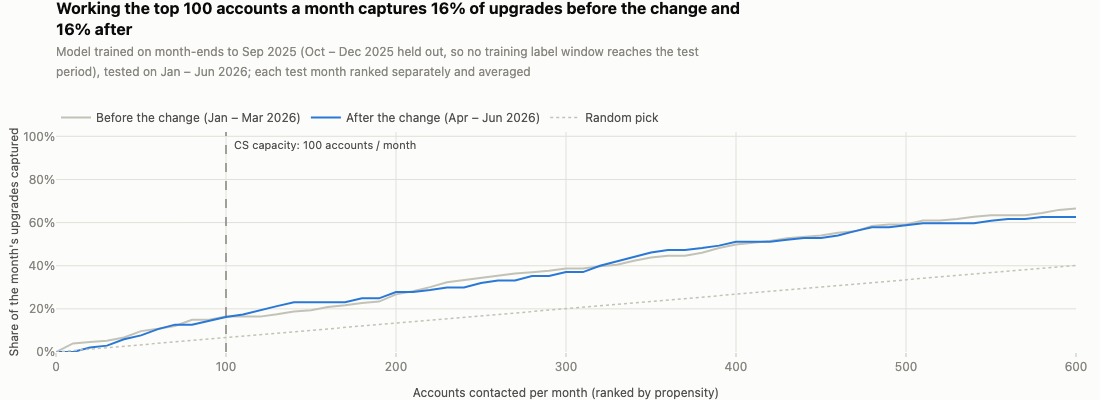

In [17]:
show(E.fig_capture_curve(100))

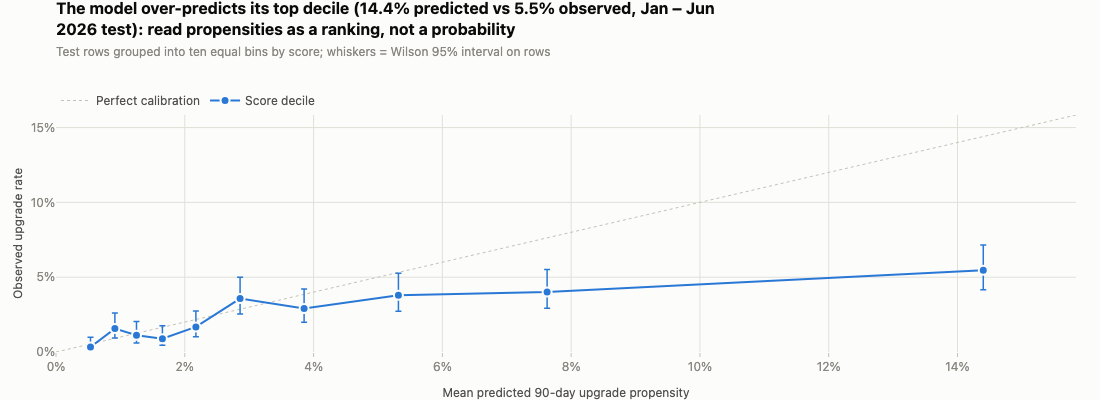

In [18]:
show(E.fig_calibration('all'))

In [19]:
cal[cal['period'] == 'all'][['decile', 'n', 'upgrades', 'predicted', 'observed', 'observed_lo', 'observed_hi']]

,decile,n,upgrades,predicted,observed,observed_lo,observed_hi
0,1,897,3,0.0054,0.0033,0.0011,0.0098
1,2,896,14,0.0091,0.0156,0.0093,0.0261
2,3,896,10,0.0125,0.0112,0.0061,0.0204
3,4,896,8,0.0165,0.0089,0.0045,0.0175
4,5,896,15,0.0217,0.0167,0.0102,0.0274
5,6,896,32,0.0286,0.0357,0.0254,0.0500
6,7,896,26,0.0385,0.0290,0.0199,0.0422
7,8,896,34,0.0532,0.0379,0.0273,0.0526
8,9,896,36,0.0763,0.0402,0.0292,0.0551
9,10,896,49,0.1440,0.0547,0.0416,0.0716


In [20]:
dc = marts.load('expansion__model_drift_check')
dc

,month_end,rows,observed,predicted_percentile_model,predicted_raw_level_model
0,2026-01-31,1311,0.0397,0.0419,0.0401
1,2026-02-28,1375,0.0298,0.0403,0.0375
2,2026-03-31,1442,0.0215,0.0407,0.0382
3,2026-04-30,1523,0.0190,0.0407,0.0478
4,2026-05-31,1603,0.0237,0.0401,0.0712
5,2026-06-30,1707,0.0211,0.0399,0.0902


In [21]:
cal_all = cal[cal['period'] == 'all']
first_over = int(cal_all.loc[cal_all['predicted'] > cal_all['observed_hi'], 'decile'].min())
ors = marts.load('expansion__odds_ratios').set_index('feature')
last = dc.iloc[-1]
md(f"""**Reading.** Trained on month-ends to Sep 2025 ({k['train_rows']:,} rows, {k['train_accounts']:,} accounts), with Oct – Dec 2025 held out
({k['embargo_rows']:,} rows) so that no training label window reaches the test period, and tested on Jan – Jun 2026 ({k['test_rows']:,} rows,
{k['test_upgrades']} upgrades), the model's AUC is {k['auc_test']:.2f} (account-level bootstrap 95% {k['auc_test_lo']:.2f}–{k['auc_test_hi']:.2f}).
{E.auc_change_sentence(k)}. The signals carry the model: per 1 SD, automation intensity multiplies the odds by
{ors.loc['automation_per_wau_pctl','odds_ratio']:.2f} ({ors.loc['automation_per_wau_pctl','or_lo']:.2f}–{ors.loc['automation_per_wau_pctl','or_hi']:.2f}), core actions per active user by
{ors.loc['log_core_actions_per_wau','odds_ratio']:.2f}, the share of paywall users by {ors.loc['gate_user_share_pctl','odds_ratio']:.2f}; tenure lowers the odds
({ors.loc['log_tenure','odds_ratio']:.2f} per 1 SD of log tenure — accounts that have stayed on Basic for years rarely move), and after these signals the Paid Social
channel ({ors.loc['is_paid_social','odds_ratio']:.2f}) and segment ({ors.loc['is_mid_market_plus','odds_ratio']:.2f}) add nothing: the channel's lower upgrade rate is explained by
behaviour.

**Capacity.** At 100 accounts a month, precision is {pct(k['precision_at_100_pre'])} ({pct(k['precision_at_100_pre_lo'])}–{pct(k['precision_at_100_pre_hi'])}) before April
(lift {k['lift_at_100_pre']:.1f}× ({k['lift_at_100_pre_lo']:.1f}–{k['lift_at_100_pre_hi']:.1f}×) over the {pct(k['base_rate_test_pre'])} base rate) and
{pct(k['precision_at_100_post'])} ({pct(k['precision_at_100_post_lo'])}–{pct(k['precision_at_100_post_hi'])}) after
(lift {k['lift_at_100_post']:.1f}× ({k['lift_at_100_post_lo']:.1f}–{k['lift_at_100_post_hi']:.1f}×) over the {pct(k['base_rate_test_post'])} base rate).
Pooled across the Jan – Jun 2026 test months, precision is {pct(k['precision_at_100_all'])} ({pct(k['precision_at_100_all_lo'])}–{pct(k['precision_at_100_all_hi'])}) and
lift is {k['lift_at_100_all']:.1f}× ({k['lift_at_100_all_lo']:.1f}–{k['lift_at_100_all_hi']:.1f}×); all intervals are 95% account-level bootstrap intervals.
Recall before / after is {pct(k['recall_at_100_pre'], 0)} / {pct(k['recall_at_100_post'], 0)}:
about {k['upgrades_per_month_at_100_all']:.0f} of the month's upgraders are on the list, worth {money(k['mrr_covered_per_month_at_100_all'])} MRR at list price. Doubling to 200
accounts raises recall to {pct(k['recall_at_200_all'], 0)} at {pct(k['precision_at_200_all'])} precision — the capture curve flattens, which is the argument for a short
CSM list plus a digital play for the rest.

**Calibration.** Deciles {', '.join(str(int(d)) for d in cal_all.loc[cal_all['predicted'].between(cal_all['observed_lo'], cal_all['observed_hi']), 'decile'])} track the observed rate (the mean prediction lies inside the decile's Wilson interval);
decile {', '.join(str(int(d)) for d in cal_all.loc[cal_all['predicted'] < cal_all['observed_lo'], 'decile'])} slightly under-predicts and deciles {', '.join(str(int(d)) for d in cal_all.loc[cal_all['predicted'] > cal_all['observed_hi'], 'decile'])} over-predict (top decile predicted {pct(top_dec['predicted'])}, observed {pct(top_dec['observed'])}).
Two reasons: the per-account weights the brief asks for over-represent short-lived accounts, and the base rate fell from {pct(k['base_rate_train'])} in the training months to
{pct(k['base_rate_test'])} in the test months. So: rank with the model, read probabilities as a ceiling, and re-centre the intercept on the latest observed rate.

**Why percentiles.** The same model with the three paywall / automation signals as raw levels predicts a *rising* propensity after April
({pct(dc.iloc[0]['predicted_raw_level_model'])} in January → {pct(last['predicted_raw_level_model'])} in June) while the observed rate fell to {pct(last['observed'])};
the percentile version stays flat ({pct(last['predicted_percentile_model'])}). A level shift that affects every account must not be read as every account becoming
more likely to upgrade.""")

**Reading.** Trained on month-ends to Sep 2025 (12,109 rows, 1,471 accounts), with Oct – Dec 2025 held out
(3,471 rows) so that no training label window reaches the test period, and tested on Jan – Jun 2026 (8,961 rows,
227 upgrades), the model's AUC is 0.68 (account-level bootstrap 95% 0.62–0.72).
AUC 0.66 (0.60–0.74) for month-ends indexed before the change and 0.69 (0.62–0.76) after — no sign the ranking degraded, though three months with 103 upgrades cannot show a small change either way (the 'before' rows' 90-day label windows run into May–June, so some of their upgrades already post-date the change). The signals carry the model: per 1 SD, automation intensity multiplies the odds by
1.57 (1.26–2.01), core actions per active user by
1.53, the share of paywall users by 1.38; tenure lowers the odds
(0.67 per 1 SD of log tenure — accounts that have stayed on Basic for years rarely move), and after these signals the Paid Social
channel (0.92) and segment (1.03) add nothing: the channel's lower upgrade rate is explained by
behaviour.

**Capacity.** At 100 accounts a month, precision is 7.0% (3.0%–10.7%) before April
(lift 2.3× (1.1–3.5×) over the 3.0% base rate) and
5.7% (2.7%–9.7%) after
(lift 2.7× (1.3–4.2×) over the 2.1% base rate).
Pooled across the Jan – Jun 2026 test months, precision is 6.3% (3.7%–9.0%) and
lift is 2.5× (1.5–3.4×); all intervals are 95% account-level bootstrap intervals.
Recall before / after is 16% / 16%:
about 6 of the month's upgraders are on the list, worth $1.3K MRR at list price. Doubling to 200
accounts raises recall to 27% at 5.2% precision — the capture curve flattens, which is the argument for a short
CSM list plus a digital play for the rest.

**Calibration.** Deciles 1, 3, 4, 5, 6, 7 track the observed rate (the mean prediction lies inside the decile's Wilson interval);
decile 2 slightly under-predicts and deciles 8, 9, 10 over-predict (top decile predicted 14.4%, observed 5.5%).
Two reasons: the per-account weights the brief asks for over-represent short-lived accounts, and the base rate fell from 4.9% in the training months to
2.5% in the test months. So: rank with the model, read probabilities as a ceiling, and re-centre the intercept on the latest observed rate.

**Why percentiles.** The same model with the three paywall / automation signals as raw levels predicts a *rising* propensity after April
(4.0% in January → 9.0% in June) while the observed rate fell to 2.1%;
the percentile version stays flat (4.0%). A level shift that affects every account must not be read as every account becoming
more likely to upgrade.

### 5. Opportunity list at 30 Sep 2026

In [22]:
cols = ['rank', 'company_name', 'customer_id', 'segment', 'cs_coverage', 'csm_owner', 'seats', 'billing_period', 'current_arr', 'next_renewal_date',
        'propensity', 'incremental_mrr_if_upgrade', 'expected_mrr', 'reason_code_1', 'reason_code_2', 'reason_code_3']
opp[cols].head(15)

,rank,company_name,customer_id,segment,cs_coverage,csm_owner,seats,billing_period,current_arr,next_renewal_date,propensity,incremental_mrr_if_upgrade,expected_mrr,reason_code_1,reason_code_2,reason_code_3
0,1,Everridge Data,CUS-003611,SMB,digital,NaN,44.0000,monthly,"7,920.0000",2026-10-06,0.0945,880.0000,83.1776,CORE_ACTIONS_TOP_DECILE,AUTOMATION_TOP_DECILE,GATE_USERS_TOP_DECILE
1,2,Primecrest Wealth,CUS-004594,Mid-Market,pooled_csm,CSM-08,39.0000,annual,"5,616.0000",2027-06-26,0.1191,624.0000,74.3261,CORE_ACTIONS_TOP_DECILE,GATE_USERS_TOP_DECILE,AUTOMATION_ABOVE_MEDIAN
2,3,Boldfield Bio,CUS-004070,Mid-Market,pooled_csm,CSM-08,38.0000,annual,"5,472.0000",2027-04-13,0.0826,608.0000,50.2092,CORE_ACTIONS_TOP_DECILE,GATE_USERS_TOP_DECILE,AUTOMATION_ABOVE_MEDIAN
3,4,Granitestack Capital,CUS-004097,Mid-Market,pooled_csm,CSM-08,25.0000,monthly,"4,500.0000",2026-10-17,0.0925,500.0000,46.2423,AUTOMATION_ABOVE_MEDIAN,GATE_USERS_TOP_DECILE,GATE_HITS_TOP_DECILE
4,5,Harborcrest Clinics,CUS-003416,Mid-Market,pooled_csm,CSM-06,50.0000,monthly,"9,000.0000",2026-10-05,0.0444,"1,000.0000",44.3973,AUTOMATION_ABOVE_MEDIAN,GATE_USERS_TOP_DECILE,GATE_HITS_ABOVE_MEDIAN
5,6,Cedarridge Learning,CUS-002299,Mid-Market,pooled_csm,CSM-07,49.0000,annual,"7,056.0000",2027-06-10,0.0512,784.0000,40.1661,CORE_ACTIONS_TOP_DECILE,GATE_USERS_TOP_DECILE,GATE_HITS_ABOVE_MEDIAN
6,7,Oakview Fabrication,CUS-004453,SMB,digital,NaN,10.0000,monthly,"1,800.0000",2026-10-09,0.1990,200.0000,39.7998,CORE_ACTIONS_TOP_DECILE,AUTOMATION_TOP_DECILE,GATE_USERS_TOP_DECILE
7,8,Harborvale Studios,CUS-004530,Mid-Market,pooled_csm,CSM-05,47.0000,annual,"6,768.0000",2027-06-20,0.0506,752.0000,38.0638,CORE_ACTIONS_ABOVE_MEDIAN,GATE_USERS_ABOVE_MEDIAN,GATE_HITS_ABOVE_MEDIAN
8,9,Willowspark Group,CUS-003354,Mid-Market,pooled_csm,CSM-08,22.0000,annual,"3,168.0000",2026-12-26,0.1061,352.0000,37.3637,CORE_ACTIONS_TOP_DECILE,GATE_USERS_TOP_DECILE,AUTOMATION_ABOVE_MEDIAN
9,10,Peakstream Cloud,CUS-003919,Mid-Market,pooled_csm,CSM-09,39.0000,annual,"5,616.0000",2027-03-25,0.0598,624.0000,37.2965,AUTOMATION_TOP_DECILE,GATE_USERS_TOP_DECILE,GATE_HITS_TOP_DECILE


In [23]:
cap = E.opportunity_summary(opp, 100)
by_cov = opp.groupby('cs_coverage').agg(accounts=('customer_id', 'size'), expected_upgrades=('propensity', 'sum'), expected_mrr=('expected_mrr', 'sum')).round(1)
md(f"""**Reading.** {k['n_opportunities']:,} Basic accounts with three or more months of tenure are paying at 30 Sep 2026. Scored with the model refit on all
labelled months and re-centred on the post-change base rate ({pct(k['deploy_post_base_rate'])}), they hold {k['opportunities_expected_upgrades']:.0f} expected voluntary upgrades
in the next 90 days, worth {money(k['opportunities_expected_mrr'])} MRR ({money(k['opportunities_incremental_mrr_if_all'])} if every account upgraded). The top 100 by expected MRR —
large Basic teams with heavy automation, high core activity and users hitting the remaining paywall — carry {cap['expected_upgrades']:.1f} expected upgrades and
{money(cap['expected_mrr'])} of expected MRR ({pct(cap['share_of_expected_mrr'], 0)} of the list's value) with propensities from {pct(cap['min_propensity'])} up to
{pct(opp['propensity'].max())}. Given the calibration result, treat these as ceilings. Reason codes are defined below; `evidence` carries the numbers behind them.""")
by_cov

**Reading.** 1,997 Basic accounts with three or more months of tenure are paying at 30 Sep 2026. Scored with the model refit on all
labelled months and re-centred on the post-change base rate (2.1%), they hold 41 expected voluntary upgrades
in the next 90 days, worth $8.0K MRR ($353K if every account upgraded). The top 100 by expected MRR —
large Basic teams with heavy automation, high core activity and users hitting the remaining paywall — carry 6.1 expected upgrades and
$2.5K of expected MRR (31% of the list's value) with propensities from 2.3% up to
19.9%. Given the calibration result, treat these as ceilings. Reason codes are defined below; `evidence` carries the numbers behind them.

,accounts,expected_upgrades,expected_mrr
cs_coverage,,,
digital,1641,32.3000,"4,591.1000"
named_csm,2,0.0000,18.6000
pooled_csm,354,9.1000,"3,422.0000"


In [24]:
marts.load('expansion__reason_codes')

,reason_code,definition
0,GATE_HITS_TOP_DECILE,Premium-feature paywall hits per active user i...
1,GATE_HITS_ABOVE_MEDIAN,Premium-feature paywall hits per active user a...
2,GATE_USERS_TOP_DECILE,Share of active users hitting the Premium payw...
3,GATE_USERS_ABOVE_MEDIAN,Share of active users hitting the Premium payw...
4,TEAM_GROWTH_10PCT_3M,Seats up 10% or more vs 3 months ago
5,TEAM_GROWING,"Seats up vs 3 months ago, by less than 10%"
6,UTIL_ABOVE_90,Seat utilization (active users / seats) of 90%...
7,UTIL_ABOVE_75,Seat utilization of 75-90% over the last 13 weeks
8,FULL_SEATS_WEEK,At least one week in the last 13 with active u...
9,INVITES_TOP_DECILE,Teammate invitations per seat in the top 10% o...


In [25]:
md(f"""## Limitations
- **Synthetic data.** Effect sizes follow the generator's rules (`docs/data_model.md §6`); the method and the leakage discipline are what transfer, not the magnitudes.
- **Correlation, not causation.** Paywall hits measure demand for Premium features; they do not show that *surfacing* the paywall causes upgrades. Only an experiment
  (an in-product prompt with a holdout) can show that.
- **Who is in the comparison.** {k['voluntary_upgrade_events'] - k['upgrade_events_in_comparison']} of {k['voluntary_upgrade_events']} voluntary upgrades are outside the matched comparison because the account was younger than three months or the window was
  not complete; the signals therefore describe upgrades of *established* Basic accounts. Stayers exclude accounts that upgraded at any time, which makes them a purer
  control and slightly flatters the gaps; the quintile lifts on the full population do not have this choice built in and tell the same story.
- **Three post-change months.** The after-April lifts and the post-change AUC rest on {k['test_upgrades_post']} upgrades; intervals are wide and the
  three month-ends' windows straddle the change, so they can show a collapse but not a small shift either way.
- **The model is a ranking tool.** The per-account weights and the falling base rate make its top deciles over-confident; expected values on the opportunity list are
  anchored on the Apr – Jun 2026 rate and are ceilings, not a forecast. A monthly list counts the same upgrade in up to three consecutive month-ends by design.
- **No outreach data.** Sales-assisted upgrades are in the label, so part of what the model "finds" may already be worked by Sales; CS touch logs would separate the two.""")

## Limitations
- **Synthetic data.** Effect sizes follow the generator's rules (`docs/data_model.md §6`); the method and the leakage discipline are what transfer, not the magnitudes.
- **Correlation, not causation.** Paywall hits measure demand for Premium features; they do not show that *surfacing* the paywall causes upgrades. Only an experiment
  (an in-product prompt with a holdout) can show that.
- **Who is in the comparison.** 185 of 532 voluntary upgrades are outside the matched comparison because the account was younger than three months or the window was
  not complete; the signals therefore describe upgrades of *established* Basic accounts. Stayers exclude accounts that upgraded at any time, which makes them a purer
  control and slightly flatters the gaps; the quintile lifts on the full population do not have this choice built in and tell the same story.
- **Three post-change months.** The after-April lifts and the post-change AUC rest on 103 upgrades; intervals are wide and the
  three month-ends' windows straddle the change, so they can show a collapse but not a small shift either way.
- **The model is a ranking tool.** The per-account weights and the falling base rate make its top deciles over-confident; expected values on the opportunity list are
  anchored on the Apr – Jun 2026 rate and are ceilings, not a forecast. A monthly list counts the same upgrade in up to three consecutive month-ends by design.
- **No outreach data.** Sales-assisted upgrades are in the label, so part of what the model "finds" may already be worked by Sales; CS touch logs would separate the two.

## Recommendations (sized in `05_recommendations`)
1. **Sales-assist + Product — P4: Premium trial for top Basic accounts by expected MRR.** Work the top 100 eligible accounts each quarter, ranked by propensity × upgrade size, with the reason codes as the opening of the conversation.
   Randomize 70% to treatment / 30% to holdout and compare 90-day voluntary upgrade rates and 6-month retention of upgraders; the holdout measures what outreach adds.
   The propensity ranking's 6.3% precision / 2.5× lift back-test is a benchmark for this list, rather than a measured result for its expected-MRR ranking.
2. **Product / Pricing:** after the packaging change, the remaining Premium gates (analytics dashboards, API, integrations beyond five) are the upgrade trigger. Test an
   in-product upgrade prompt that fires when an account's paywall users reach the top decile for the month, with a randomized holdout; report the upgrade rate and
   the Basic retention of prompted vs unprompted accounts to the December pricing council.
3. **RevOps:** re-base every signal threshold quarterly as a percentile of the current Basic population, refit the model each quarter, and publish the calibration
   table (predicted vs observed by decile) with the account health list so the expected values stay honest.

**What data I would want next:** user-level gate events naming the gated feature; CS and Sales touch logs to separate outreach-driven upgrades; post-upgrade Premium
feature usage to confirm the value delivered; and a randomized holdout on any packaging or prompt change.